
Tamaños: (5, 5, 5, 5, 5); n=25; μ=0.600000
Separaciones entre centros (°): [72. 72. 72. 72. 72.]
Gradiente: 2.641e-15; menor autovalor sin rotación: 2.13525492
Dispersión interna máxima: 0.000e+00°; error frente al flujo: 8.882e-16 rad
No sincronizado y no equidistante: False
Conclusión: mínimo estricto salvo rotación: evidencia numérica

Tamaños: (5, 5, 5, 5, 6); n=26; μ=0.576923
Separaciones entre centros (°): [82.819244 82.819244 55.771134 55.771134 82.819244]
Gradiente: 7.854e-15; menor autovalor sin rotación: 0.98676366
Dispersión interna máxima: 0.000e+00°; error frente al flujo: 1.776e-15 rad
No sincronizado y no equidistante: True
Conclusión: mínimo estricto salvo rotación: evidencia numérica

Tamaños: (5, 6, 5, 6, 5); n=27; μ=0.592593
Grupos fusionados: sincronización.
Gradiente: 0.000e+00; menor autovalor sin rotación: 6.75500200
Dispersión interna máxima: 0.000e+00°; error frente al flujo: 0.000e+00 rad
No sincronizado y no equidistante: False
Conclusión: mínimo estricto sa

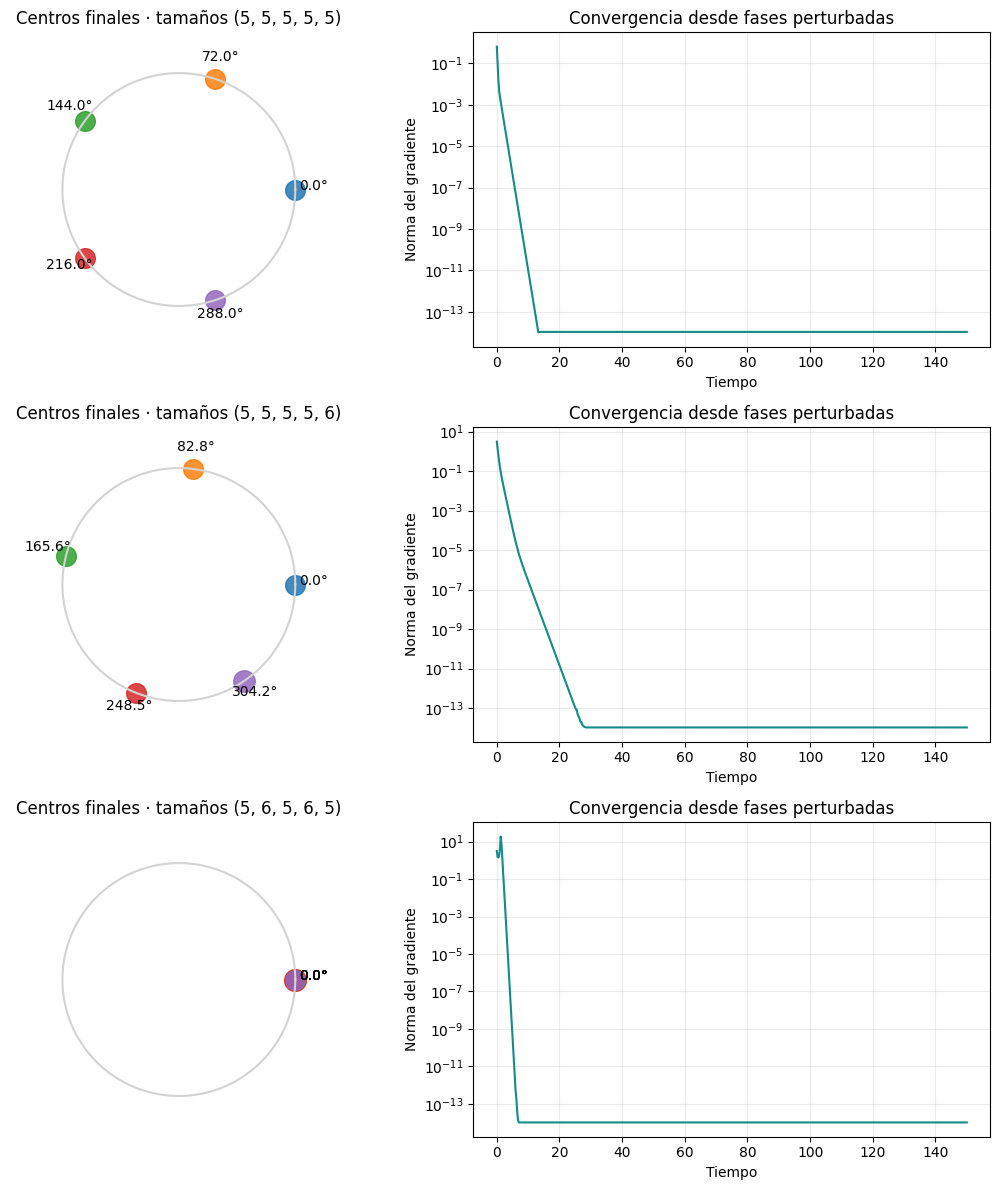

In [ ]:
#1. ¿Qué pasa si los clústeres no son equidistantes?
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root
from scipy.linalg import null_space

# Colab: ejecutar esta celda. Todas las interacciones tienen peso 1.
CASOS = [(5, 5, 5, 5, 5), (5, 5, 5, 5, 6), (5, 6, 5, 6, 5)]
SEMILLA = 42

def grafo(tamanos):
    grupos = np.repeat(np.arange(len(tamanos)), tamanos)
    distancia = (grupos[:, None] - grupos[None, :]) % len(tamanos)
    A = np.isin(distancia, [0, 1, len(tamanos)-1]).astype(float)
    np.fill_diagonal(A, 0)
    return A, grupos

def gradiente(theta, A):
    return np.sum(A * np.sin(theta[:, None] - theta[None, :]), axis=1)

def hessiano(theta, A):
    W = A * np.cos(theta[:, None] - theta[None, :])
    return np.diag(W.sum(axis=1)) - W

def energia(theta, A):
    return .5 * np.sum(A * (1 - np.cos(theta[:, None] - theta[None, :])))

def circular(x):
    return (x + np.pi) % (2*np.pi) - np.pi

resultados = []
fig, axes = plt.subplots(len(CASOS), 2, figsize=(11, 4*len(CASOS)))
for fila, tamanos in enumerate(CASOS):
    A, grupos = grafo(tamanos)
    n = len(grupos)
    rng = np.random.default_rng(SEMILLA)
    # Perturbaciones independientes en TODOS los nodos: no se impone agrupamiento.
    inicial = 2*np.pi*grupos/5 + rng.uniform(-.03, .03, n)
    sol = solve_ivp(lambda t, th: -gradiente(th, A), (0, 150), inicial,
                    method='DOP853', max_step=0.1, rtol=1e-9, atol=1e-11,
                    t_eval=np.linspace(0, 150, 601))
    if not sol.success:
        raise RuntimeError(sol.message)
    # Refinamos el equilibrio fijando theta_0 = 0; luego verificamos TODO el gradiente.
    estimado = sol.y[:, -1] - sol.y[0, -1]
    ajuste = root(lambda z: gradiente(np.r_[0., z], A)[1:], estimado[1:],
                  jac=lambda z: hessiano(np.r_[0., z], A)[1:, 1:], tol=1e-11)
    theta = np.r_[0., ajuste.x]
    residual = np.linalg.norm(gradiente(theta, A))
    Q = null_space(np.ones((1, n)))
    eig = np.linalg.eigvalsh(Q.T @ hessiano(theta, A) @ Q)
    centros = np.array([np.angle(np.mean(np.exp(1j*theta[grupos == j]))) for j in range(5)])
    dispers = max(np.max(np.abs(circular(theta[grupos == j]-centros[j]))) for j in range(5))
    centros_ordenados = np.sort(centros % (2*np.pi))
    intervalos = np.diff(np.r_[centros_ordenados, centros_ordenados[0]+2*np.pi])*180/np.pi
    sincronizado = np.abs(np.mean(np.exp(1j*theta))) > 1-1e-8
    desigual = (not sincronizado) and np.ptp(intervalos) > .01  # diferencia > 0.01 grados
    estable = residual < 1e-8 and eig[0] > 1e-6
    # Comprobación numérica independiente con tolerancias más estrictas.
    sol2 = solve_ivp(lambda t, th: -gradiente(th, A), (0, 150), inicial,
                    method='DOP853', max_step=0.1, rtol=1e-11, atol=1e-13)
    dif = sol2.y[:, -1]-theta
    error_flujo = np.max(np.abs(circular(dif-np.angle(np.mean(np.exp(1j*dif))))))
    registro = dict(tamanos=tamanos, n=n, mu=(A.sum(axis=1).min()+1)/n,
                    intervalos=intervalos, gradiente=residual, autovalor=eig[0],
                    dispersion_grados=np.rad2deg(dispers), error_flujo=error_flujo,
                    estable=estable, sincronizado=sincronizado, no_equidistante=desigual, energia=energia(theta,A))
    resultados.append(registro)
    print(f'\nTamaños: {tamanos}; n={n}; μ={registro["mu"]:.6f}')
    print('Grupos fusionados: sincronización.' if sincronizado else 'Separaciones entre centros (°): '+str(np.round(intervalos, 6)))
    print(f'Gradiente: {residual:.3e}; menor autovalor sin rotación: {eig[0]:.8f}')
    print(f'Dispersión interna máxima: {np.rad2deg(dispers):.3e}°; error frente al flujo: {error_flujo:.3e} rad')
    print('No sincronizado y no equidistante:', not sincronizado and desigual)
    print('Conclusión:', 'mínimo estricto salvo rotación: evidencia numérica' if estable else 'sin certificado numérico de mínimo')
    ax = axes[fila,0]
    ang=np.linspace(0,2*np.pi,400)
    ax.plot(np.cos(ang),np.sin(ang),color='lightgray')
    for j in range(5):
        ax.scatter(np.cos(centros[j]),np.sin(centros[j]),s=40*tamanos[j],label=f'Grupo {j+1}: {tamanos[j]} nodos',alpha=.85)
        ax.text(1.16*np.cos(centros[j]),1.16*np.sin(centros[j]),f'{round(np.rad2deg(centros[j])%360,1)%360:.1f}°',ha='center')
    ax.set_aspect('equal'); ax.set_xlim(-1.45,1.45); ax.set_ylim(-1.35,1.35)
    ax.set_title(f'Centros finales · tamaños {tamanos}'); ax.axis('off')
    vals = np.array([np.linalg.norm(gradiente(th,A)) for th in sol.y.T])
    axes[fila,1].semilogy(sol.t,np.maximum(vals,1e-14),color='#138b88')
    axes[fila,1].set(title='Convergencia desde fases perturbadas',xlabel='Tiempo',ylabel='Norma del gradiente')
    axes[fila,1].grid(alpha=.25)
plt.tight_layout()
plt.show()


GRAFOS SIMPLES CON EQUILIBRIO SEGUIDO
+  0 aristas | μ=0.576923 | λmin=0.98676366 | grad=7.72e-15 | dispersión=0.000°
+  1 aristas | μ=0.576923 | λmin=0.43891389 | grad=5.96e-12 | dispersión=6.326°
+  2 aristas | μ=0.576923 | λmin=0.72309355 | grad=3.18e-13 | dispersión=6.531°
+  3 aristas | μ=0.576923 | λmin=0.49672880 | grad=3.40e-14 | dispersión=7.001°

ARISTAS COMPLETADAS (índices desde cero): [(7, 22), (5, 19), (8, 18)]

PUNTO DE DETENCIÓN: {'tipo': 'seguimiento_no_resuelto', 'paso': 4, 'arista': (10, 20), 'alpha_ultimo': 0.654392578125, 'alpha_intento': 0.6548216796874999, 'mu_ultimo_simple': np.float64(0.5769230769230769), 'mu_siguiente_simple': np.float64(0.5769230769230769), 'residual_intento': 2.6141494745342726e-05, 'salto_intento': 0.003597714653310824}

DINÁMICA CON LA SIGUIENTE ARISTA COMPLETA: {'mu': np.float64(0.5769230769230769), 'grad': 7.265778991250518e-15, 'lambda_min': 7.25878992990459, 'r': 1.0000000000000002, 'dispersion': 0.0, 'separacion_min': 0.0}

IMPORTANTE

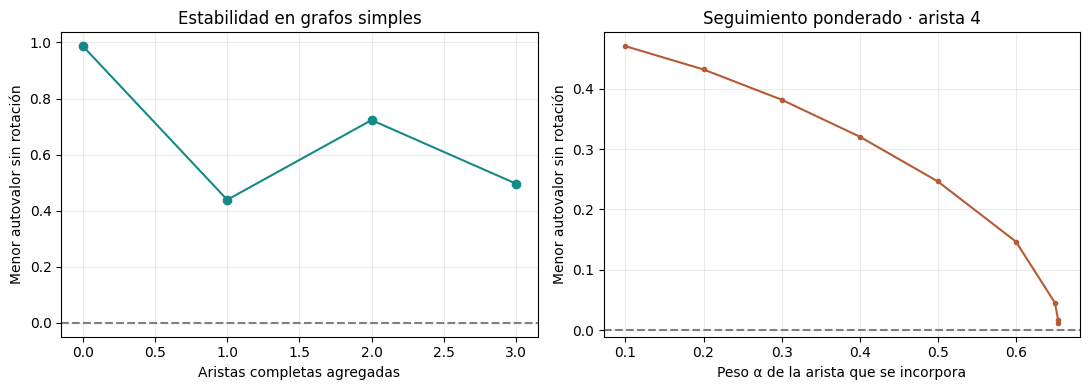

In [ ]:
#2. Encontrar el mu(G) crítico por el cual se rompe la estabilidad de uno o más mínimos no sincronizados dada una agrupación de "l" clústeres
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root
from scipy.integrate import solve_ivp
from scipy.linalg import null_space

TAMANOS = (5, 5, 5, 5, 6)
SEMILLA_ARISTAS = 42
TOL_GRAD = 1e-8
TOL_ESTABILIDAD = 1e-7
MIN_PASO = 1/4096

def wrap(x):
    return (x + np.pi) % (2*np.pi) - np.pi

def grad(theta, A):
    return np.sum(A*np.sin(theta[:,None]-theta[None,:]), axis=1)

def hess(theta, A):
    W=A*np.cos(theta[:,None]-theta[None,:])
    return np.diag(W.sum(axis=1))-W

def resolver(A, previo):
    r=root(lambda z: grad(np.r_[0.,z],A)[1:], previo[1:],
           jac=lambda z:hess(np.r_[0.,z],A)[1:,1:], tol=1e-10)
    th=np.r_[0.,r.x]
    # Escoger representantes cercanos a los anteriores sin cambiar fases físicas.
    th=previo+wrap(th-previo)
    return th, np.linalg.norm(grad(th,A))

grupo=np.repeat(np.arange(5),TAMANOS)
n=len(grupo)
d=(grupo[:,None]-grupo[None,:])%5
A=np.isin(d,[0,1,4]).astype(float)
np.fill_diagonal(A,0)
Q=null_space(np.ones((1,n)))
base=2*np.pi*grupo/5
sol=solve_ivp(lambda t,th:-grad(th,A),(0,60),base,rtol=1e-10,atol=1e-12,max_step=.1)
theta,res=resolver(A,sol.y[:,-1]-sol.y[0,-1])
assert res<TOL_GRAD
rng=np.random.default_rng(SEMILLA_ARISTAS)
prioridad=rng.random((n,n))

def medir(A,theta):
    eig=np.linalg.eigvalsh(Q.T@hess(theta,A)@Q)
    centros=np.array([np.angle(np.mean(np.exp(1j*theta[grupo==j]))) for j in range(5)])
    dispersion=max(np.max(np.abs(wrap(theta[grupo==j]-centros[j]))) for j in range(5))
    orden=np.sort(centros%(2*np.pi))
    separaciones=np.diff(np.r_[orden,orden[0]+2*np.pi])
    return dict(mu=(A.sum(axis=1).min()+1)/n,
                grad=float(np.linalg.norm(grad(theta,A))),lambda_min=float(eig[0]),
                r=float(abs(np.mean(np.exp(1j*theta)))),
                dispersion=float(np.rad2deg(dispersion)),
                separacion_min=float(np.rad2deg(separaciones.min())))

registros=[dict(aristas_agregadas=0,**medir(A,theta))]
trayectoria=[]
log_aristas=[]
incidencia=None
for paso in range(1,int((n*(n-1)-A.sum())/2)+1):
    grados=A.sum(axis=1)
    faltantes=list(zip(*np.where(np.triu(1-A,1)>0)))
    # Priorizar extremos de menor grado; desempate reproducible.
    u,v=min(faltantes,key=lambda e:(min(grados[e[0]],grados[e[1]]),
                                    max(grados[e[0]],grados[e[1]]),prioridad[e]))
    B=A.copy(); B[u,v]=B[v,u]=1
    mu_siguiente=(B.sum(axis=1).min()+1)/n
    # Homotopía solo como herramienta de seguimiento: arista 0 -> 1.
    # Los puntos intermedios son PONDERADOS; no son nuevos grafos simples.
    alpha=0.; incremento=.1
    while alpha < 1-1e-12:
        objetivo=min(1.,alpha+incremento)
        W=A.copy();W[u,v]=W[v,u]=objetivo
        candidato,res=resolver(W,theta)
        salto=np.max(np.abs(wrap(candidato-theta)))
        if res>TOL_GRAD or salto>.10:
            incremento/=2
            if incremento<MIN_PASO:
                incidencia=dict(tipo='seguimiento_no_resuelto',paso=paso,arista=(int(u),int(v)),
                                alpha_ultimo=alpha,alpha_intento=objetivo,
                                mu_ultimo_simple=registros[-1]['mu'],mu_siguiente_simple=mu_siguiente,
                                residual_intento=float(res),salto_intento=float(salto))
                break
            continue
        theta=candidato;alpha=objetivo
        m=medir(W,theta)
        trayectoria.append(dict(paso=paso,alpha=alpha,**m))
        if m['lambda_min']<=TOL_ESTABILIDAD:
            incidencia=dict(tipo='estabilidad_estricta_no_certificada',paso=paso,arista=(int(u),int(v)),
                            alpha=alpha,lambda_min=m['lambda_min'],
                            mu_ultimo_simple=registros[-1]['mu'],mu_siguiente_simple=mu_siguiente)
            break
        incremento=min(.1,incremento*1.3)
    if incidencia is not None:
        break
    A=B
    log_aristas.append((int(u),int(v)))
    registros.append(dict(aristas_agregadas=paso,**medir(A,theta)))

print('GRAFOS SIMPLES CON EQUILIBRIO SEGUIDO')
for z in registros:
    print(f"+{z['aristas_agregadas']:3d} aristas | μ={z['mu']:.6f} | λmin={z['lambda_min']:.8f} | grad={z['grad']:.2e} | dispersión={z['dispersion']:.3f}°")
print('\nARISTAS COMPLETADAS (índices desde cero):',log_aristas)
print('\nPUNTO DE DETENCIÓN:',incidencia)
if incidencia is not None:
    prueba=solve_ivp(lambda t,th:-grad(th,B),(0,150),theta,method='DOP853',
                    rtol=1e-10,atol=1e-12,max_step=.1)
    final=prueba.y[:,-1]
    diagnostico=medir(B,final)
    print('\nDINÁMICA CON LA SIGUIENTE ARISTA COMPLETA:',diagnostico)

print('\nIMPORTANTE: detener el seguimiento no demuestra inexistencia del equilibrio ni sincronización global.')
print('La dispersión se mide respecto de las cinco etiquetas originales: después de agregar aristas ya no imponemos clústeres exactos.')

fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot([z['aristas_agregadas'] for z in registros],[z['lambda_min'] for z in registros],'o-',color='#168a88')
axs[0].axhline(0,color='gray',linestyle='--')
axs[0].set(xlabel='Aristas completas agregadas',ylabel='Menor autovalor sin rotación',title='Estabilidad en grafos simples')
if trayectoria:
    ultimo=trayectoria[-1]['paso']
    datos=[z for z in trayectoria if z['paso']==ultimo]
    axs[1].plot([z['alpha'] for z in datos],[z['lambda_min'] for z in datos],'.-',color='#b65b35')
    axs[1].axhline(0,color='gray',linestyle='--')
    axs[1].set(xlabel='Peso α de la arista que se incorpora',ylabel='Menor autovalor sin rotación',title=f'Seguimiento ponderado · arista {ultimo}')
for ax in axs:ax.grid(alpha=.25)
plt.tight_layout();plt.show()
